# Tutorial 02: SVD, interpolation, preconditioning, FFT (no spins)

Continuing from chapter 01, this chapter reproduces the second half of the BUILD stage, i.e. the blocks "SVD of the table and interpolation of the basis" and "constants of the Lambda-dependent part" of `__init__`:

| Section | Source variables | Content |
|---|---|---|
| 1 | `A`, `sx` | flatten the table into a matrix; row scale $\varsigma_t$ |
| 2 | `colw`, `u, sv, vt`, `rank` | column weights, SVD, truncation |
| 3 | `coef`, `B` | split into basis and coefficients → `fo._C` |
| 4 | `spl`, `spl_s`, `s_f`, `B_f` | interpolate the basis to the fine grid → `fo._B` |
| 5 | `xa`, `_FJ`, `_L2` | preconditioning $x^{7/3}$ and FFT → `fo._FJ` |
| 6 | `_cell`, `_zw`, `_e4l`, `_L1` | constants used by every call |

Notation: $t$ = table row ($\ln x_t$), $s$ = $q$ node, $r$ = SVD mode, $m$ = fine $x$ grid.

In [1]:
import os
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[k] = "1"

In [2]:
%matplotlib inline
import sys
sys.path.append("../")
FIGDIR = "../../Figures/"

In [3]:
import numpy as np
import matplotlib.pyplot as plt

import seaborn as sns
sns.set(style='ticks', context='notebook', font='serif', 
        font_scale=1.5, palette='deep')
plt.rcParams.update({
    "text.usetex": True,
    "text.latex.preamble": r"\usepackage{amssymb}\usepackage{mathrsfs}\usepackage{bm}", 
    "font.family": "serif",
    'backend': 'pdf',
    # Grid
    "axes.grid": True,
    "grid.alpha": 0.7,
    "grid.linewidth": 0.4,

    # Ticks
    "xtick.direction": "in",
    "ytick.direction": "in",
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    # Font
    'font.size': 18,
    'legend.fontsize': 18,
})

import jax
jax.config.update("jax_enable_x64", True)
from scipy.interpolate import CubicSpline

from stochaxtic.fast_omega import FastOmega, T_SUN, A_PRE, _next_fast_len, _fix_signs
from stochaxtic.constants import YR_S, Z_MAX_DEFAULT

def check(name, mine, ref):
    mine, ref = np.asarray(mine), np.asarray(ref)
    assert mine.shape == ref.shape, (name, mine.shape, ref.shape)
    rel = np.max(np.abs(mine - ref)) / np.max(np.abs(ref))      # relative to the largest entry
    print(f"{name:24s} shape {str(ref.shape):16s} max |diff| / max |ref| = {rel:.1e}")
    return rel

fo = FastOmega()                                 # same default set-up as chapter 01
Jcols = fo.table()[:, :, 0]      # split axis dropped: (n_q, n_kappa, n_spin, n_xJ) = (121, 1, 1, 1007)
ln_xJ, ln_x, wq = fo.ln_xJ, fo.ln_x, fo.wq
n_q, n_k, n_s = Jcols.shape[:3]
print(Jcols.shape)

FastOmega: SVD loaded from /home/haowen.zhong/.cache/stochaxtic/svd_IMRPhenomXAS_f596ad348a1a949f.npz
FastOmega: IMRPhenomXAS, spins=None, tides=False: 121 table columns, rank 8; grids lnM 1231, z 444, lnq 121, lnf 1061; setup 0.1 s
(121, 1, 1, 1007)


## 1. Flatten the table into a matrix; row scale $\varsigma_t$

`Jcols` is a 4-d array `(n_q, n_kappa, n_spin, n_xJ)`. `reshape(-1, n_xJ)` merges the first three indices into one "column" index **in the order (q, κ, spin)**; after the transpose, the matrix $J_{t,\rm col}$ has rows $x_t$ and columns $(s,c,i)$. Without spins and tides the columns are just $s$.

$\varsigma_t$ is the **RMS** of each row over all columns (not the standard deviation: no mean is subtracted):
$$\varsigma_t=\Big[\tfrac{1}{n_{\rm col}}\sum_{\rm col}J_{t,\rm col}^2\Big]^{1/2}.$$
The rows after the ringdown are all zero, $\varsigma_t=0$; the normalisation sets them to 0 (`np.where`).

In [4]:
A = Jcols.reshape(-1, len(ln_xJ)).T                      # (n_xJ, n_col)
sx = np.sqrt(np.mean(A ** 2, axis=1))                     # varsigma_t
An = np.where(sx[:, None] > 0, A / np.where(sx > 0, sx, 1.0)[:, None], 0.0)
print("A:", A.shape, "  rows with varsigma = 0:", np.sum(sx == 0))
print(f"varsigma spans {sx[sx > 0].min():.1e} ... {sx.max():.1e}  ({np.log10(sx.max() / sx[sx > 0].min()):.0f} decades)")

A: (1007, 121)   rows with varsigma = 0: 123
varsigma spans 5.1e-64 ... 4.1e-42  (22 decades)


## 2. Column weights, SVD, truncation

The column weights are $c_s=\sqrt{w_s/n_{\rm spin}}$ (without spins $n_{\rm spin}=1$, so just $\sqrt{w_s}$). The matrix that goes into the SVD is
$$\mathsf{J}_{ts}=\frac{J_{ts}}{\varsigma_t}\sqrt{w_s}=\sum_r U_{tr}\sigma_rV_{sr}.$$
`np.linalg.svd` returns `u`$=U$, `sv`$=\sigma$, `vt`$=V^{\mathsf T}$ (note that `vt[r, s]` $=V_{sr}$). FastOmega obtains the same decomposition without holding the table in memory (`_streaming_svd`: a QR factorisation of $A^{\mathsf T}$ stacked chunk by chunk gives $R$, whose SVD has the singular values and left vectors of $A$; the right vectors follow from $V^{\mathsf T}=\Sigma^{-1}U^{\mathsf T}A$). Each singular pair is defined up to a sign; `_fix_signs` fixes it (largest entry of every left vector positive), which is why the code below can compare with `fo._C` entry by entry.

Truncation rule: keep the modes with $\sigma_r/\sigma_1>$ `rank_tol` $=10^{-4}$, at most 96 (there is no lower bound). The no-spin table is very "smooth" ($J$ changes slowly with $q$), its singular values fall off fast, and only 8 modes pass the tolerance.

rank = 8  (fo: 8 )
normalised sigma         shape (121,)           max |diff| / max |ref| = 8.1e-17


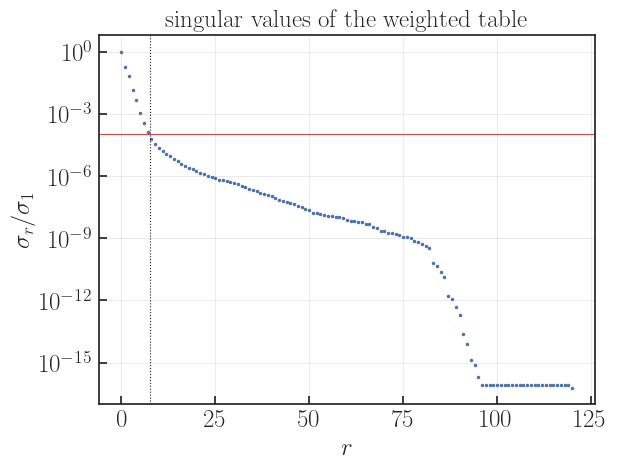

In [5]:
live_rows = sx > 0
colw = np.sqrt(np.repeat(wq, n_k * n_s) / n_s)            # c_s
u, sv, vt = np.linalg.svd(An * colw[None, :], full_matrices=False)
rank_tol = 1e-4
rank = int(min(96, max(1, np.sum(sv / sv[0] > rank_tol))))
print("rank =", rank, " (fo:", fo.info["rank"], ")")
check("normalised sigma", sv / sv[0], fo._sv)

plt.semilogy(sv / sv[0], ".", ms=3)
plt.axhline(rank_tol, color="r", lw=0.8); plt.axvline(rank - 0.5, color="k", ls=":", lw=0.8)
plt.xlabel(r"$r$"); plt.ylabel(r"$\sigma_r / \sigma_1$"); plt.title("singular values of the weighted table");

## 3. Basis and coefficients

$$C_{rs}=\frac{V_{sr}}{c_s}\quad(\texttt{coef}),\qquad \texttt{B}=U_{tr}\sigma_r .$$

⚠️ The code's `B` does **not yet** include $\varsigma_t$: ' $B_{tr}=\varsigma_tU_{tr}\sigma_r$ defined in the paper only gets its $\varsigma_t$ after the interpolation of section 4. The reason: $U\sigma$ is a smooth O(1) function, well suited to spline interpolation, while $\varsigma_t$ spans more than twenty decades and is interpolated more accurately on its own, as a logarithm.

`coef` reshaped to `(rank, n_q, n_t, n_spin)` is `fo._C` ($n_t$ = number of tide nodes, 1 here). FastOmega stores the same numbers **q-major**, as `fo._Cq` of shape `(n_q, rank·n_t, n_spin)`, so that the spin average of chapter 04 is a batched matrix–vector product without a transpose; `fo._C` is a property that returns a copy in the order used here.

In [6]:
B, vt_r = _fix_signs(u[:, :rank] * sv[:rank], vt[:rank]) 

In [7]:
B, vt_r = _fix_signs(u[:, :rank] * sv[:rank], vt[:rank])   # U sigma, still WITHOUT varsigma
coef = (vt_r / colw[None, :]).reshape(rank, n_q, n_k, n_s)
check("coef  ->  fo._C", coef, fo._C)

# sanity: the factorisation reproduces the table, J_ts = varsigma_t * sum_r (U sigma)_tr C_rs
J_rec = sx[:, None] * (B @ coef[:, :, 0, 0])
J_tab = A
# error measured against the row scale varsigma_t: this is what the SVD controls
e_row = np.where(live_rows[:, None], np.abs(J_rec - J_tab) / np.where(live_rows, sx, 1.0)[:, None], 0.0)
print(f"rank-{rank} reconstruction: max |J_rec - J| / varsigma_t = {e_row.max():.1e},  median {np.median(e_row[live_rows]):.1e}")

coef  ->  fo._C          shape (8, 121, 1, 1)   max |diff| / max |ref| = 1.3e-12
rank-8 reconstruction: max |J_rec - J| / varsigma_t = 1.3e-03,  median 9.4e-06


Text(0, 0.5, '$B_r(x)$')

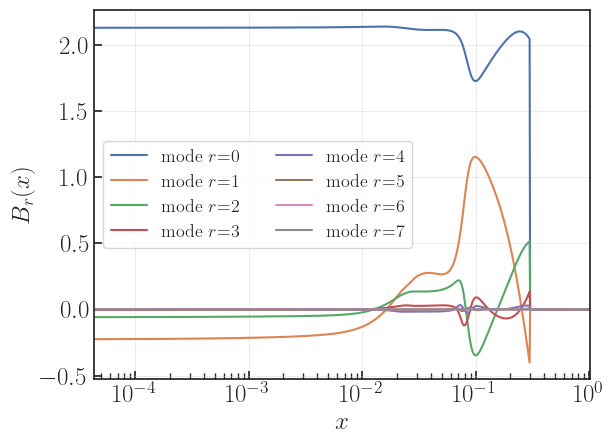

In [8]:
for r in range(8):
    plt.semilogx(np.exp(ln_xJ), B[:, r], label=rf"mode $r$={r}")
plt.xlim(np.exp(ln_xJ)[0], np.exp(ln_xJ)[-1])
plt.legend(ncol=2, fontsize=13)
plt.xlabel(r"$x$")
plt.ylabel(r"$B_r(x)$")

### Truncation error across $x$

Look row by row. Since each row was divided by $\varsigma_t$, the SVD controls the error **relative to the row's scale**, $|J_{\rm rec}-J|/\varsigma_t$, and **all rows are treated alike**: even where $J$ is twenty decades smaller, in the ringdown, the error (relative to the row) is similar to that in the inspiral. That is the point of the row normalisation of section 1.

⚠️ Do not judge it by the element-wise relative error $|J_{\rm rec}/J-1|$. In the row at $x\approx0.09$ the $q=0.01$ system is already deep in its ringdown, with $J$ only $3\times10^{-5}$ of the row scale, while the other $q$ are still merging. Such entries, much smaller than their row, have a small absolute error but an O(1) relative error, and an equally negligible contribution to $\Omega$.

(0.0001, 1)

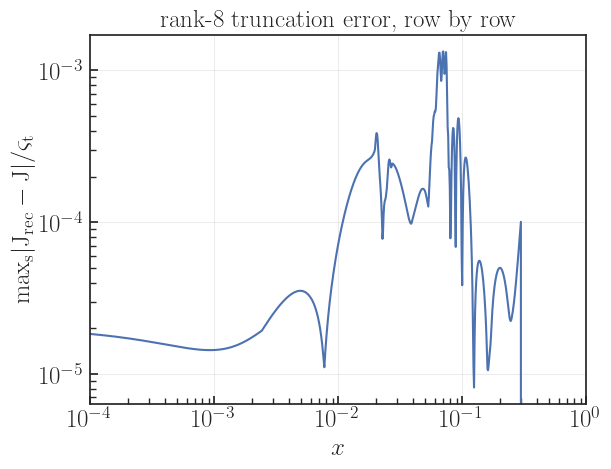

In [9]:
err_row = e_row.max(axis=1)
plt.semilogy(np.exp(ln_xJ), err_row)
plt.xscale("log"); plt.xlabel(r"$x$"); plt.ylabel(r"$\rm{max}_s |J_{\rm rec} - J| / \varsigma_t$")
plt.title(f"rank-{rank} truncation error, row by row");
plt.xlim(1e-4, 1)

**Exercise**: remove the row normalisation (take the SVD of `A * colw` directly), keep the same rank, and see how large the error becomes at high $x$ (merger and ringdown, $x\gtrsim0.03$). Without $\varsigma_t$ the SVD only cares about the numerically largest part, the inspiral, and the rows after the merger are almost ignored.

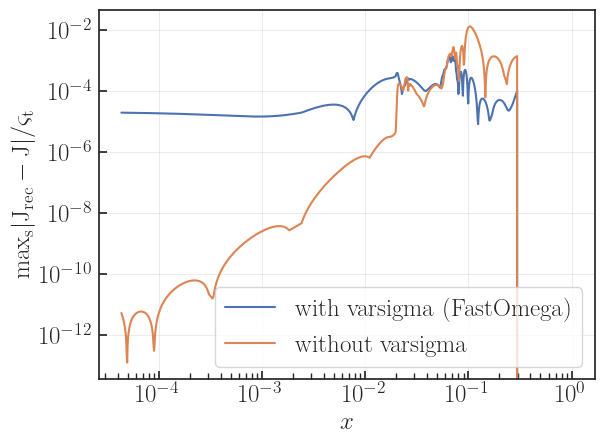

In [10]:
u0, sv0, vt0 = np.linalg.svd(A * colw[None, :], full_matrices=False)
J0 = (u0[:, :rank] * sv0[:rank]) @ (vt0[:rank] / colw[None, :])
err0 = np.where(live_rows, np.abs(J0 - J_tab).max(axis=1) / np.where(live_rows, sx, 1.0), 0.0)
plt.semilogy(np.exp(ln_xJ), err_row, label="with varsigma (FastOmega)")
plt.semilogy(np.exp(ln_xJ), err0, label="without varsigma")
plt.xscale("log"); plt.xlabel(r"$x$"); plt.ylabel(r"$\rm max_s |J_{rec} - J| / \varsigma_t$"); plt.legend();

## 4. Interpolating the basis to the fine grid $\ln x_m$

Three steps:
1. `CubicSpline(ln_xJ, B)`: a cubic spline of the O(1) function $U\sigma$;
2. `CubicSpline(ln_xJ[live], ln sx[live])`: a cubic spline of $\ln\varsigma$ in $\ln x$ through the live nodes only ($\varsigma>0$), then exponentiated. $\varsigma$ is a smooth positive function spanning many decades, so its logarithm is the variable to interpolate. A *linear* interpolation of $\ln\varsigma$ (the first version of the code) is not enough: near the merger $\ln\varsigma$ is curved, and the points midway between table nodes came out biased, which shifted $\Omega$ by about $-4\times10^{-4}$ at 1 kHz;
3. beyond the last live node `xe` (the last row with $\varsigma>0$), $\varsigma$ is set to 0: the waveform has ended there.

So $B_{mr}=\varsigma(x_m)\,\big[U\sigma\big](x_m)$, of shape $(n_x,R)=(2734,8)$; that is `fo._B`.

Text(0, 0.5, '$\\varsigma_x$')

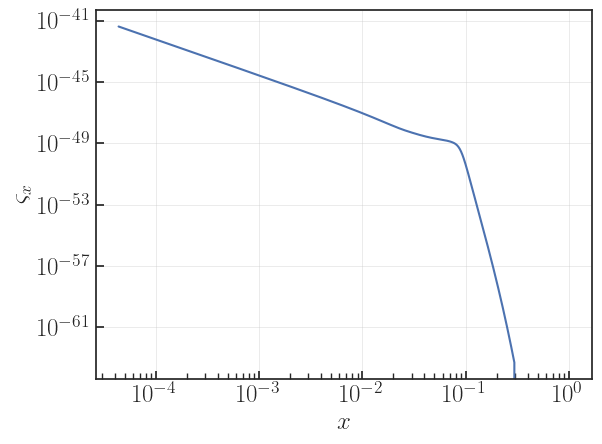

In [11]:
plt.loglog(np.exp(ln_xJ), sx)
plt.xlabel(r"$x$")
plt.ylabel(r"$\varsigma_x$")

Text(0, 0.5, '$\\ln \\varsigma_x$')

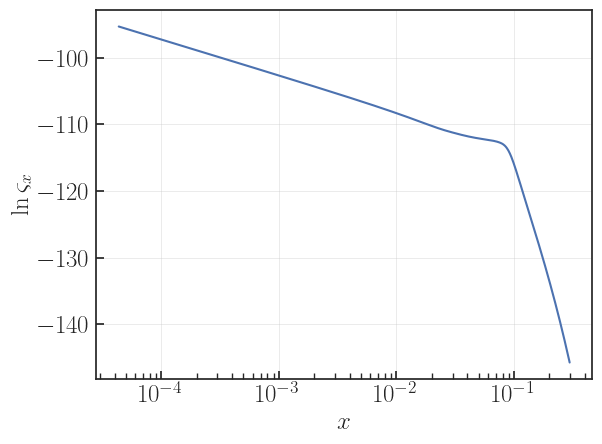

In [12]:
live = sx > 0
xe = ln_xJ[live][-1]                                     # last live table node

plt.semilogx(np.exp(ln_xJ)[live], np.log(sx[live]))
plt.xlabel(r"$x$")
plt.ylabel(r"$\ln \varsigma_x$")

In [13]:
live = sx > 0
xe = ln_xJ[live][-1]                                     # last live table node
spl = CubicSpline(ln_xJ, B, axis=0)
spl_s = CubicSpline(ln_xJ[live], np.log(sx[live]))       # ln varsigma, live nodes only
ok = ln_x <= xe
s_f = np.zeros(len(ln_x))
s_f[ok] = np.exp(spl_s(ln_x[ok]))
B_f = spl(ln_x) * s_f[:, None]
check("B_f  ->  fo._B", B_f, fo._B)

# for comparison: linear interpolation of ln varsigma
s_lin = np.exp(np.interp(ln_x[ok], ln_xJ[live], np.log(sx[live])))
print("max |linear / spline - 1| of varsigma:", np.max(np.abs(s_lin / s_f[ok] - 1)))

B_f  ->  fo._B           shape (2734, 8)        max |diff| / max |ref| = 3.7e-15
max |linear / spline - 1| of varsigma: 0.0012440040119839901


### How accurate is the interpolation?

The fine step is $\delta$ and the table step is $2\delta$, with `ln_xJ[2] == ln_x[0]`. So **every other** fine point falls exactly on a table node, where the interpolation is exact; the other half sit midway between two nodes, where the error is largest. Compute one column of true values as in chapter 01 and compare at the midpoints:

/home/haowen.zhong/StochAXtic/StochAXtic/tutorials/../stochaxtic/orientation.py:103: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


median midpoint error: 2.1640739446437962e-05


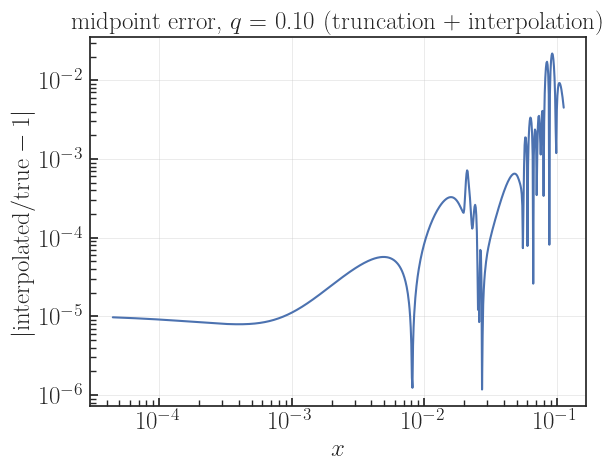

In [14]:
from stochaxtic.orientation import OrientationAverager
avg = OrientationAverager("IMRPhenomXAS")
m_ref, x_ref = fo.info["m_ref"], fo.info["x_ref"]
s = 60 
q = np.exp(fo.lq[s])
m1, m2 = m_ref / (1 + q), m_ref * q / (1 + q)
mid = slice(1, None, 2)                                  # fine points halfway between table nodes
xm = np.exp(ln_x[mid]) 
keep = xm < 0.5
true = avg(xm[keep] / (m_ref * T_SUN), m1, m2, (0, 0, 0), (0, 0, 0), f_ref=x_ref / (m_ref * T_SUN)) / m_ref ** 4
fast = (B_f @ coef[:, s, 0, 0])[mid][keep]
good = true > 1e-12 * true.max()
plt.loglog(xm[keep][good], np.abs(fast[good] / true[good] - 1))
plt.xlabel(r"$x$"); plt.ylabel(r"$\rm |interpolated / true - 1|$")
plt.title(rf"midpoint error, $q$ = {q:.2f} (truncation + interpolation)");
print("median midpoint error:", np.median(np.abs(fast[good] / true[good] - 1)))

## 5. Preconditioning and FFT

In the inspiral $J\propto x^{-7/3}$. Multiplying by $x^A$ ($A=7/3$) flattens this trend:
$$\tilde B_{mr}=B_{mr}\,x_m^{A}.$$
Because $x=T_\odot M_{\rm det}f$, this factor can be moved elsewhere **exactly**: the mass side gets $M_{\rm det}^{4-A}$ (`_e4l`, section 6), and the frequency side gets $(T_\odot f)^{-A}$ back at the end (chapter 03).

Then a zero-padded FFT along $m$. The length `L2` is the smallest power of 2 that is $\ge n_d+n_x-1$: the "linear" length of the correlation is $n_d+n_x-1$, and a shorter FFT would wrap around (circular convolution). `rfft` keeps only the non-negative frequencies, hence `L2/2+1` rows.

L2 = 8192  (n_d + n_x - 1 = 4407 )
FFT  ->  fo._FJ          shape (4097, 8)        max |diff| / max |ref| = 7.3e-16


(np.float64(4.432941852877136e-05), np.float64(38.135208912181255))

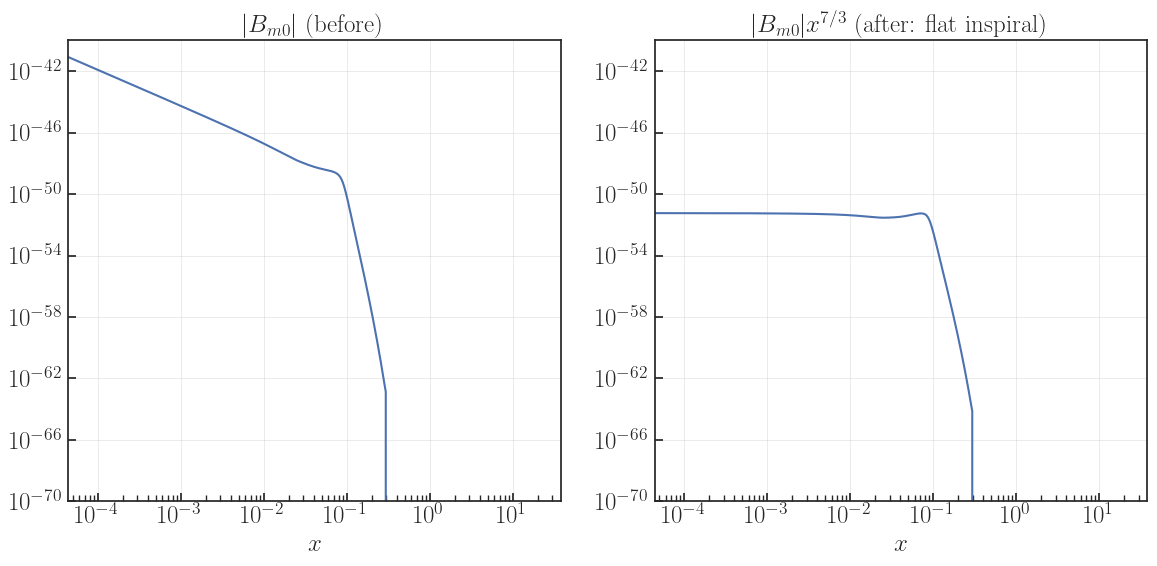

In [15]:
n_d = len(fo.l_det)
L2 = _next_fast_len(n_d + len(ln_x) - 1)
xa = np.exp(A_PRE * ln_x)[:, None]
FJ = np.fft.rfft(B_f * xa, n=L2, axis=0)
print("L2 =", L2, " (n_d + n_x - 1 =", n_d + len(ln_x) - 1, ")")
check("FFT  ->  fo._FJ", FJ, fo._FJ)

r0 = 0
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].semilogy(np.exp(ln_x), np.abs(B_f[:, r0]) + 1e-300); ax[0].set_xscale("log")
ax[0].set(title=r"$|B_{m0}|$ (before)", xlabel=r"$x$")
ax[1].semilogy(np.exp(ln_x), np.abs(B_f[:, r0] * xa[:, 0]) + 1e-300); ax[1].set_xscale("log")
ax[1].set(title=r"$|B_{m0}| x^{7/3}$ (after: flat inspiral)", xlabel=r"$x$"); plt.tight_layout();
ax[0].set_ylim(1e-70, 1e-40)
ax[1].set_ylim(1e-70, 1e-40)

ax[0].set_xlim(np.exp(ln_x)[0],np.exp(ln_x)[-1])
ax[1].set_xlim(np.exp(ln_x)[0],np.exp(ln_x)[-1])

## 6. Constants used by every call

These do not depend on any hyperparameter, so they are also computed in the constructor:

| Variable | Formula | Use (chapter 03) |
|---|---|---|
| `_cell` | $\delta\,w_s$ | turns a density in $(\ln M,\ln q)$ into a probability per cell |
| `_zw` | $w^{(\xi)}_j\,\dfrac{dV_c/dz}{d_L^2}\,\dfrac{1}{10^9\cdot{\rm yr\,[s]}}$ | redshift weight $\zeta_j$; times $\mathcal R(z)$ it is $\rho_j$ |
| `_e4l` | $e^{(4-A)\ell^{\rm det}_d}=(M^{\rm det}_d)^{4-A}$ | the remaining mass power of $I=M^4J$ |
| `_L1` | power of 2 $\ge n_\ell+n_z-1$ | FFT length of the redshift convolution |

Where `_zw` comes from: the number of events per unit time and unit $\xi$ is $\frac{dN}{dz}\frac{dz}{d\xi}$, with $\frac{dN}{dz}=\frac{\mathcal R}{1+z}\frac{dV_c}{dz}$ and $\frac{dz}{d\xi}=1+z$; the two factors $(1+z)$ cancel. Then multiply by the flux factor $1/d_L^2$. Units: $\mathcal R$ is in Gpc$^{-3}$yr$^{-1}$, while $dV_c/dz$ is in Mpc$^3$ and $d_L$ in Mpc (`cosmology.py`), so `1e9` converts Gpc$^3$ to Mpc$^3$ and `YR_S` converts per year to per second.

In [16]:
d = fo.info["delta"]
n_l, n_z = len(fo.l_src), len(fo.z)
# trapezoid weights in xi = ln(1+z), as in chapter 01
xi1 = np.log1p(Z_MAX_DEFAULT)
wxi = np.full(n_z, d); wxi[0] *= 0.5; wxi[-1] = 0.5 * d + (xi1 - fo.xi[-1])

cell = d * wq[None, :]
dL = fo.cosmo.luminosity_distance(fo.z)
zw = wxi * fo.cosmo.dVc_dz(fo.z) / dL ** 2 / (1e9 * YR_S)
e4l = np.exp((4 - A_PRE) * fo.l_det)[:, None]
L1 = _next_fast_len(n_l + n_z - 1)

check("cell  ->  fo._cell", cell, fo._cell)
check("zw    ->  fo._zw", zw, fo._zw)
check("e4l   ->  fo._e4l", e4l, fo._e4l)
print("L1 =", L1, "(fo:", fo._L1, ")   L2 =", L2, "(fo:", fo._L2, ")")

cell  ->  fo._cell       shape (1, 121)         max |diff| / max |ref| = 0.0e+00
zw    ->  fo._zw         shape (444,)           max |diff| / max |ref| = 0.0e+00
e4l   ->  fo._e4l        shape (1674, 1)        max |diff| / max |ref| = 0.0e+00
L1 = 2048 (fo: 2048 )   L2 = 8192 (fo: 8192 )


## Summary

The **BUILD stage is now fully reproduced**. When the constructor returns, FastOmega keeps only these arrays:

| Variable | Meaning | Shape (default, no spins) |
|---|---|---|
| `_Cq` | coefficients $C_{rs}$ ($C_{r,(si)}$ with spins), q-major; `fo._C` returns them as `(rank, n_q, n_t, n_spin)` | (121, 8, 1); `_C`: (8, 121, 1, 1) |
| `_B` | basis $B_{mr}$ on the fine grid | (2734, 8) |
| `_FJ` | $\mathrm{FFT}_m[B_{mr}x_m^{7/3}]$ | (4097, 8) |
| `_cell`, `_zw`, `_e4l` | mass-cell probability, redshift measure, mass power | (1,121), (444,), (1674,1) |
| `_L1`, `_L2` | lengths of the two FFTs | 2048, 8192 |

The 121 waveforms (and the raw J table) are **never used again**: every call uses only the small arrays above.

**Next chapter (03)**: given a mass model and a redshift model, reproduce `omega()` line by line (mass density → projection onto the modes → redshift convolution → frequency cross-correlation → $\Omega_{\rm GW}(f)$) and compare with `fo.omega(...)`.